In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

# Locate dataset
possible_paths = [
    Path("data/raw"),
    Path("../data/raw")
]

DATA_DIR = next(
    (p for p in possible_paths if (p / "train.csv").exists()),
    None
)

if DATA_DIR is None:
    raise FileNotFoundError("PSM dataset not found")

# Load datasets
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
test_label_df = pd.read_csv(DATA_DIR / "test_label.csv")

feature_cols = [
    col for col in train_df.columns
    if col.startswith("feature_")
]

print("Dataset loaded successfully!")
print("Number of features:", len(feature_cols))

Dataset loaded successfully!
Number of features: 25


In [2]:
# Generate descriptive statistics

eda_summary = train_df[feature_cols].describe().T

# Add missing value information
eda_summary["missing_count"] = (
    train_df[feature_cols].isnull().sum()
)

eda_summary["missing_percentage"] = (
    train_df[feature_cols].isnull().mean() * 100
)

display(eda_summary.round(4))

,count,mean,std,min,25%,50%,75%,max,missing_count,missing_percentage
feature_0,132481.0,0.8358,0.0673,0.4865,0.7895,0.8373,0.8806,1.0000,0,0.0000
feature_1,132481.0,0.8402,0.0395,0.5257,0.8205,0.8439,0.8664,0.9100,0,0.0000
feature_2,132481.0,0.6342,0.1029,0.4215,0.5802,0.6033,0.6258,1.0000,0,0.0000
feature_3,132481.0,0.5751,0.0497,0.3809,0.5437,0.5721,0.6111,0.6767,0,0.0000
feature_4,132279.0,0.5433,0.0894,0.0651,0.4711,0.5484,0.6049,0.9294,202,0.1525
feature_5,132232.0,0.5118,0.0778,0.1102,0.4514,0.5074,0.5597,0.8775,249,0.1880
feature_6,131918.0,0.5493,0.0641,0.2159,0.5057,0.5398,0.5795,1.0000,563,0.4250
feature_7,132434.0,0.5377,0.0901,0.0778,0.4709,0.5298,0.5884,0.9683,47,0.0355
feature_8,132434.0,0.5511,0.0790,0.0387,0.4908,0.5523,0.6036,0.9351,47,0.0355
feature_9,132481.0,0.5452,0.0810,0.0404,0.4826,0.5456,0.5989,0.9160,0,0.0000


In [3]:
print("TRAINING TIMESTAMP RANGE")

print("First timestamp:",
      train_df["timestamp_(min)"].iloc[0])

print("Last timestamp:",
      train_df["timestamp_(min)"].iloc[-1])

print("\nTEST TIMESTAMP RANGE")

print("First timestamp:",
      test_df["timestamp_(min)"].iloc[0])

print("Last timestamp:",
      test_df["timestamp_(min)"].iloc[-1])

print("\nTimestamp sorted:",
      train_df["timestamp_(min)"].is_monotonic_increasing)

print("\nTraining/Test boundary:")

print("Training last timestamp:",
      train_df["timestamp_(min)"].iloc[-1])

print("Testing first timestamp:",
      test_df["timestamp_(min)"].iloc[0])

TRAINING TIMESTAMP RANGE
First timestamp: 0.0
Last timestamp: 132480.0

TEST TIMESTAMP RANGE
First timestamp: 132480.0
Last timestamp: 220320.0

Timestamp sorted: True

Training/Test boundary:
Training last timestamp: 132480.0
Testing first timestamp: 132480.0


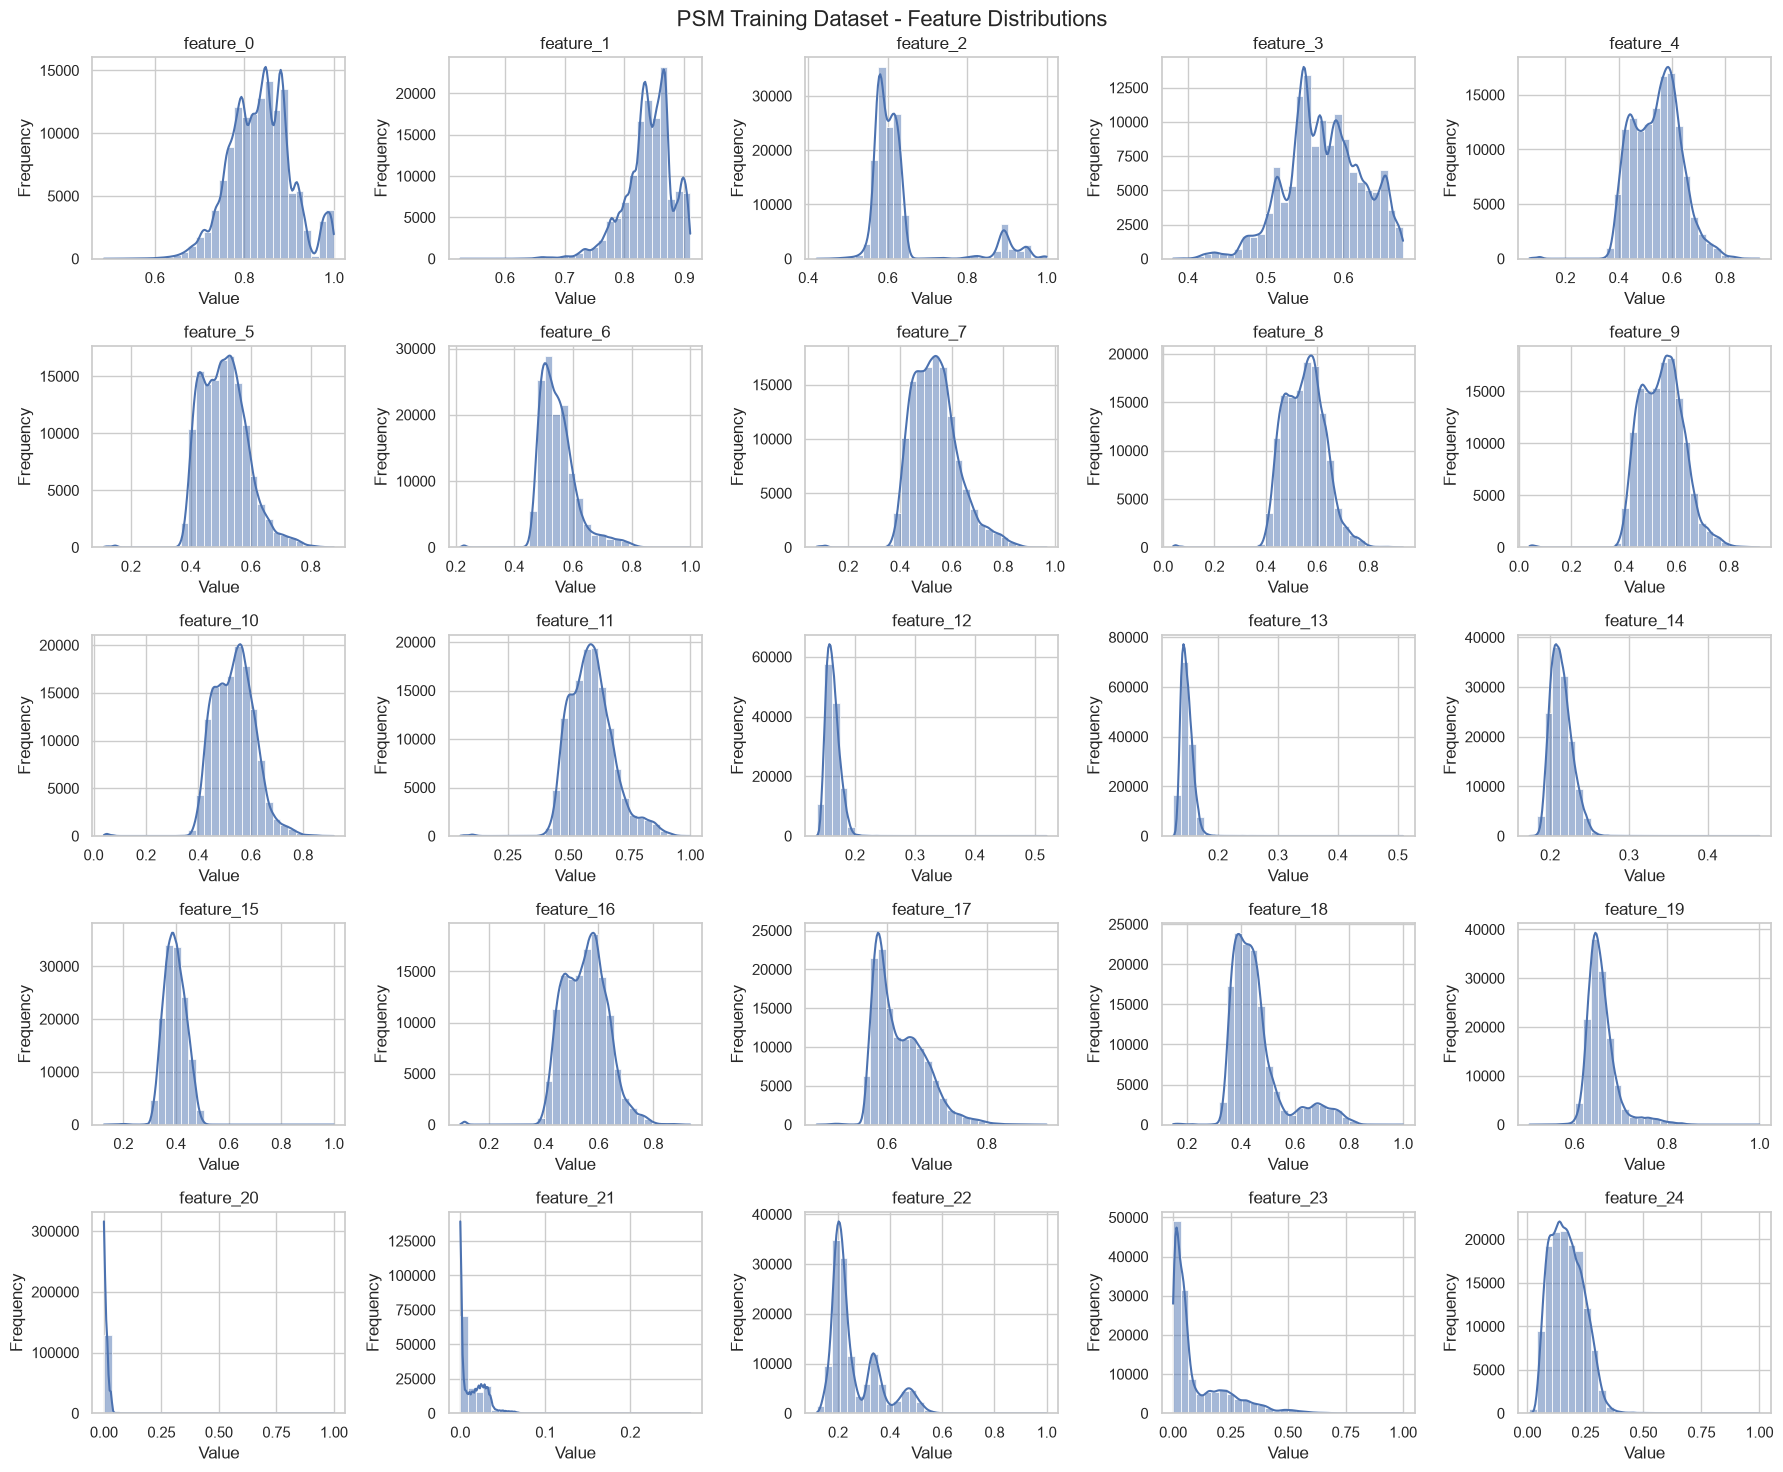

In [4]:
# Plot feature distributions

fig, axes = plt.subplots(
    5, 5,
    figsize=(18, 15)
)

for i, col in enumerate(feature_cols):

    ax = axes[i // 5, i % 5]

    sns.histplot(
        train_df[col].dropna(),
        bins=30,
        kde=True,
        ax=ax
    )

    ax.set_title(col)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")

plt.suptitle(
    "PSM Training Dataset - Feature Distributions",
    fontsize=16
)

plt.tight_layout()
plt.show()

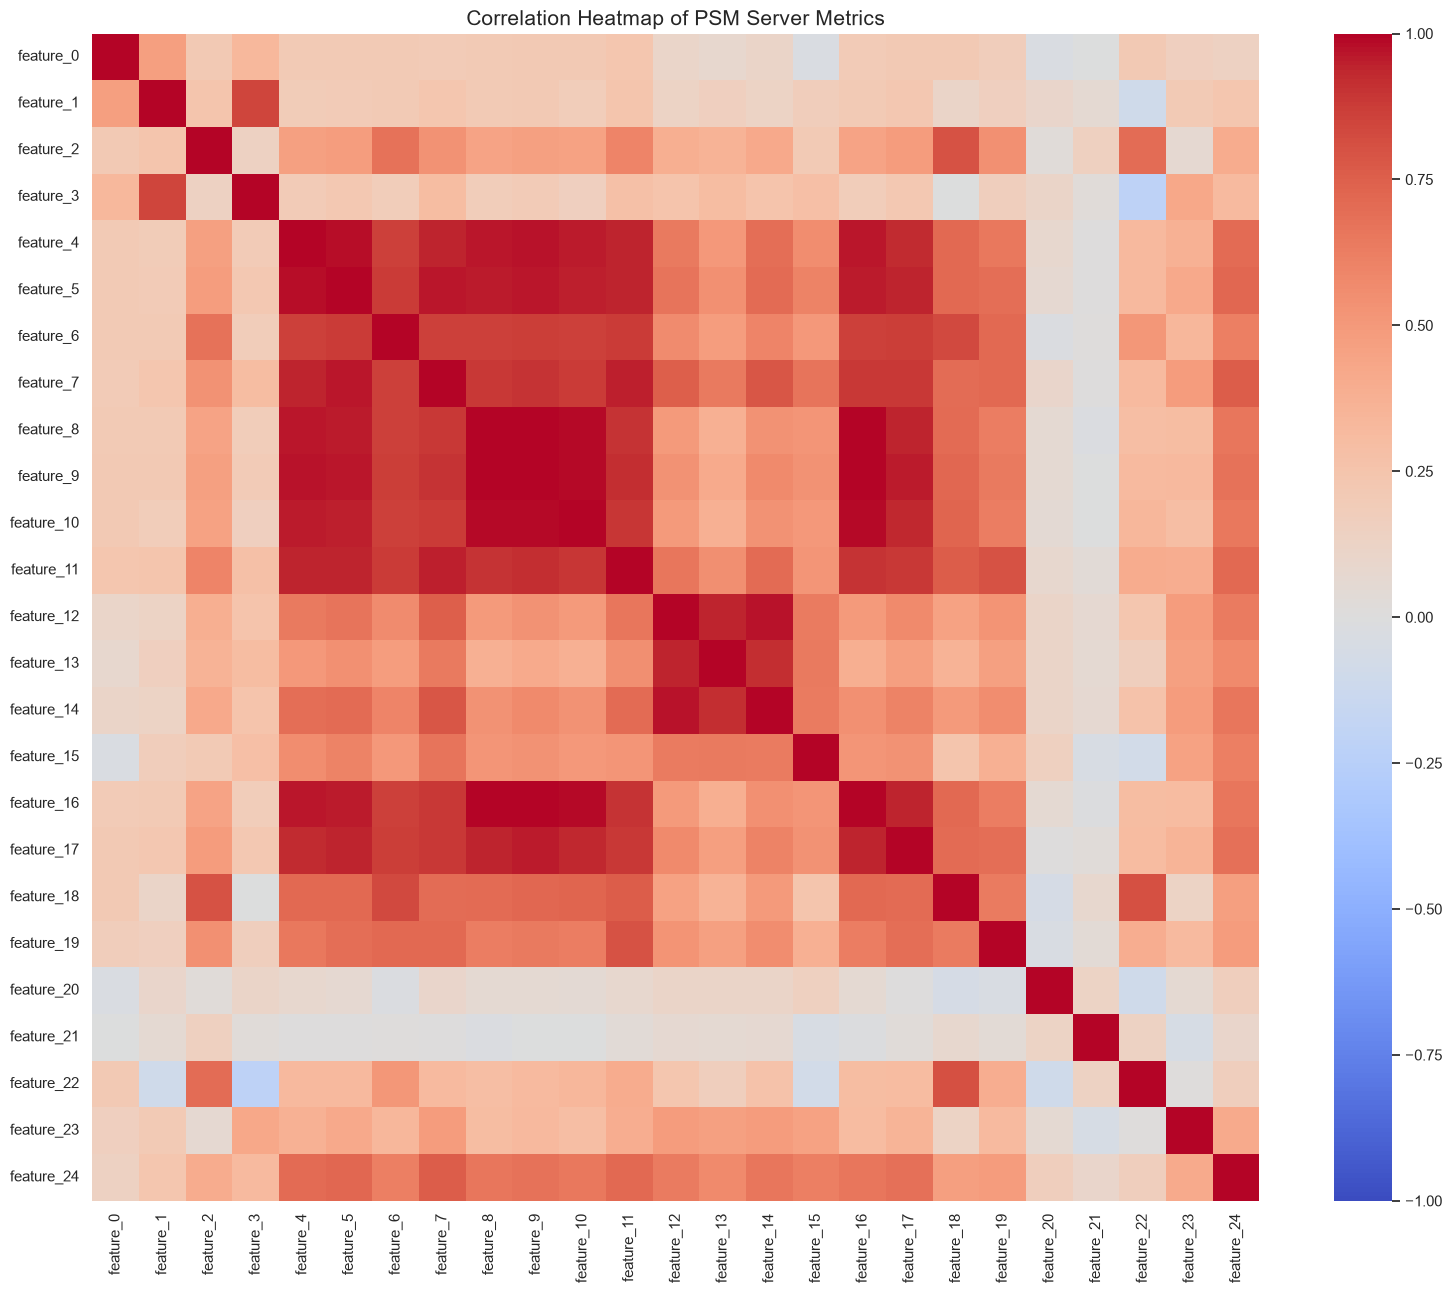

In [5]:
# Calculate feature correlations

correlation_matrix = train_df[
    feature_cols
].corr()

plt.figure(figsize=(16, 13))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title(
    "Correlation Heatmap of PSM Server Metrics",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [6]:
# Check the shared timestamp between training and testing

timestamp_col = "timestamp_(min)"

train_last = train_df.iloc[-1]
test_first = test_df.iloc[0]

print("TRAINING LAST RECORD")
display(train_last)

print("TESTING FIRST RECORD")
display(test_first)


# Compare feature values

train_values = train_last[feature_cols].astype(float)
test_values = test_first[feature_cols].astype(float)

same_values = np.allclose(
    train_values,
    test_values,
    equal_nan=True
)

print("\nAre all feature values identical?")
print(same_values)


# Count matching feature values

matching_features = np.isclose(
    train_values,
    test_values,
    equal_nan=True
).sum()

print(
    "Matching features:",
    matching_features,
    "/",
    len(feature_cols)
)


# Verify test labels and timestamps

print("\nTEST DATA AND LABEL ALIGNMENT")

print(
    "Timestamps match:",
    np.array_equal(
        test_df[timestamp_col].to_numpy(),
        test_label_df[timestamp_col].to_numpy()
    )
)


# Check timestamp duplicates within each split

print("\nDUPLICATE TIMESTAMPS")

print(
    "Training:",
    train_df[timestamp_col].duplicated().sum()
)

print(
    "Testing:",
    test_df[timestamp_col].duplicated().sum()
)

TRAINING LAST RECORD


timestamp_(min)    132480.000000
feature_0               0.775374
feature_1               0.909185
feature_2               0.606704
feature_3               0.660626
feature_4               0.449968
feature_5               0.426717
feature_6               0.471591
feature_7               0.434668
feature_8               0.479511
feature_9               0.478078
feature_10              0.465794
feature_11              0.516738
feature_12              0.157978
feature_13              0.148025
feature_14              0.207122
feature_15              0.400617
feature_16              0.480444
feature_17              0.588670
feature_18              0.404036
feature_19              0.638957
feature_20              0.020236
feature_21              0.042705
feature_22              0.173375
feature_23              0.008715
feature_24              0.105991
Name: 132480, dtype: float64

TESTING FIRST RECORD


timestamp_(min)    132480.000000
feature_0               0.775374
feature_1               0.909185
feature_2               0.606704
feature_3               0.660626
feature_4               0.449968
feature_5               0.426717
feature_6               0.471591
feature_7               0.434668
feature_8               0.479511
feature_9               0.478078
feature_10              0.465794
feature_11              0.516738
feature_12              0.157978
feature_13              0.148025
feature_14              0.207122
feature_15              0.400617
feature_16              0.480444
feature_17              0.588670
feature_18              0.404036
feature_19              0.638957
feature_20              0.020236
feature_21              0.042705
feature_22              0.173375
feature_23              0.008715
feature_24              0.105991
Name: 0, dtype: float64


Are all feature values identical?
True
Matching features: 25 / 25

TEST DATA AND LABEL ALIGNMENT
Timestamps match: True

DUPLICATE TIMESTAMPS
Training: 0
Testing: 0


In [7]:
# Handle duplicated training/testing boundary record

timestamp_col = "timestamp_(min)"

train_last = train_df.iloc[-1]
test_first = test_df.iloc[0]

# Verify exact boundary duplication

same_timestamp = (
    train_last[timestamp_col] == test_first[timestamp_col]
)

same_features = np.allclose(
    train_last[feature_cols].astype(float),
    test_first[feature_cols].astype(float),
    equal_nan=True
)

boundary_duplicate = same_timestamp and same_features

print("Boundary duplicate:", boundary_duplicate)

# Preserve original datasets
# Create separate evaluation copies

if boundary_duplicate:

    test_eval_df = test_df.iloc[1:].copy().reset_index(drop=True)

    test_label_eval_df = (
        test_label_df.iloc[1:].copy().reset_index(drop=True)
    )

else:

    test_eval_df = test_df.copy().reset_index(drop=True)

    test_label_eval_df = (
        test_label_df.copy().reset_index(drop=True)
    )

print("\nOriginal test records:", len(test_df))
print("Evaluation test records:", len(test_eval_df))

print("Original labels:", len(test_label_df))
print("Evaluation labels:", len(test_label_eval_df))

print("\nEvaluation timestamps aligned:",
      np.array_equal(
          test_eval_df[timestamp_col].to_numpy(),
          test_label_eval_df[timestamp_col].to_numpy()
      ))

print("\nExcluded first label:",
      test_label_df.iloc[0]["label"])

Boundary duplicate: True

Original test records: 87841
Evaluation test records: 87840
Original labels: 87841
Evaluation labels: 87840

Evaluation timestamps aligned: True

Excluded first label: 0.0


In [8]:
# Calculate feature correlations

corr_matrix = train_df[feature_cols].corr()

# Extract unique feature pairs

upper_triangle = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

corr_pairs = (
    upper_triangle.stack()
    .rename("correlation")
    .reset_index()
)

corr_pairs.columns = [
    "feature_1",
    "feature_2",
    "correlation"
]

# Sort by absolute correlation

corr_pairs["absolute_correlation"] = (
    corr_pairs["correlation"].abs()
)

top_correlations = corr_pairs.sort_values(
    by="absolute_correlation",
    ascending=False
).head(15)

print("TOP 15 CORRELATED FEATURE PAIRS")

display(top_correlations.round(4))

TOP 15 CORRELATED FEATURE PAIRS


,feature_1,feature_2,correlation,absolute_correlation
216,feature_8,feature_16,0.9974,0.9974
209,feature_8,feature_9,0.9956,0.9956
241,feature_9,feature_16,0.9936,0.9936
210,feature_8,feature_10,0.9907,0.9907
235,feature_9,feature_10,0.9885,0.9885
266,feature_10,feature_16,0.9883,0.9883
105,feature_4,feature_5,0.9828,0.9828
314,feature_12,feature_14,0.9761,0.9761
109,feature_4,feature_9,0.9733,0.9733
134,feature_5,feature_9,0.9671,0.9671
